# Linear Regression - MPG prediction

### 1. Business Undestanding

In [1]:
# MPG prediction using MT_cars dataset

### 2. Data Collection

#### 2.1. Import nesessary library and dataset

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

cars_data = pd.read_csv('cars.csv')

### 3. Data Understanding

#### 3.1 perform Initial investigation on the data

In [3]:
# shape 
cars_data.shape
print(cars_data.shape)

# Null check
cars_data.isna().sum()
print(cars_data.isna().sum())

# duplicates check 
cars_data.duplicated
print(cars_data.duplicated)

# data types
cars_data.dtypes
print(cars_data.dtypes)

# describe
cars_data.describe()

(81, 5)
HP     0
MPG    0
VOL    0
SP     0
WT     0
dtype: int64
<bound method DataFrame.duplicated of      HP        MPG  VOL          SP         WT
0    49  53.700681   89  104.185353  28.762059
1    55  50.013401   92  105.461264  30.466833
2    55  50.013401   92  105.461264  30.193597
3    70  45.696322   92  113.461264  30.632114
4    53  50.504232   92  104.461264  29.889149
..  ...        ...  ...         ...        ...
76  322  36.900000   50  169.598513  16.132947
77  238  19.197888  115  150.576579  37.923113
78  263  34.000000   50  151.598513  15.769625
79  295  19.833733  119  167.944460  39.423099
80  236  12.101263  107  139.840817  34.948615

[81 rows x 5 columns]>
HP       int64
MPG    float64
VOL      int64
SP     float64
WT     float64
dtype: object


,HP,MPG,VOL,SP,WT
count,81.000000,81.000000,81.000000,81.000000,81.000000
mean,117.469136,34.422076,98.765432,121.540272,32.412577
std,57.113502,9.131445,22.301497,14.181432,7.492813
min,49.000000,12.101263,50.000000,99.564907,15.712859
25%,84.000000,27.856252,89.000000,113.829145,29.591768
50%,100.000000,35.152727,101.000000,118.208698,32.734518
75%,140.000000,39.531633,113.000000,126.404312,37.392524
max,322.000000,53.700681,160.000000,169.598513,52.997752


### Check for assumption

#### Test 1: Linearity test

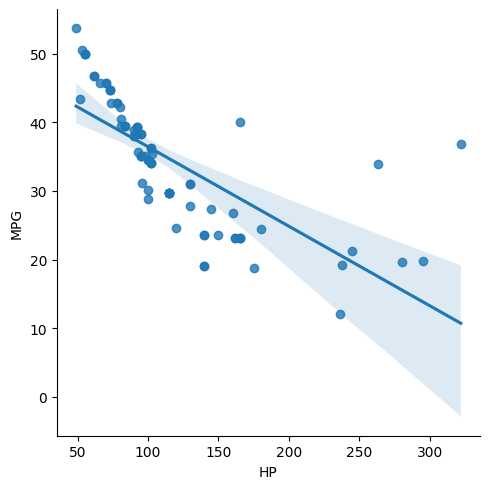

In [4]:
sns.lmplot(data =cars_data , x='HP',y='MPG')

<Axes: xlabel='HP', ylabel='MPG'>

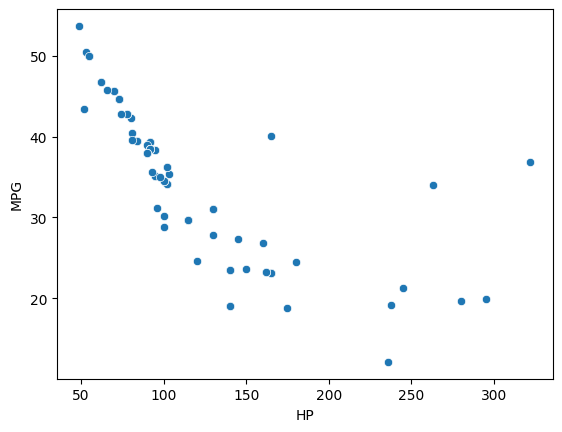

In [5]:
sns.scatterplot(data =cars_data , x='HP',y='MPG')

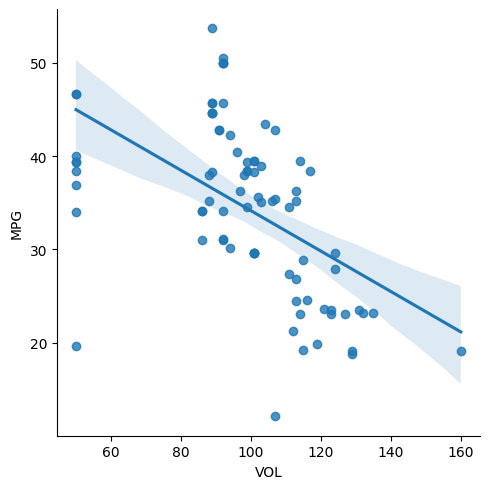

In [6]:
sns.lmplot(data =cars_data , x='VOL',y='MPG')

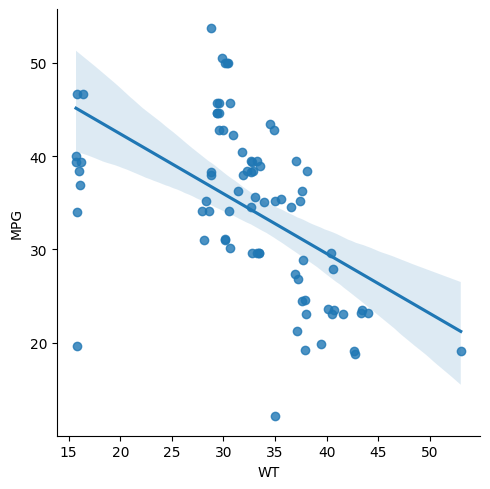

In [7]:
sns.lmplot(data =cars_data , x='WT',y='MPG')

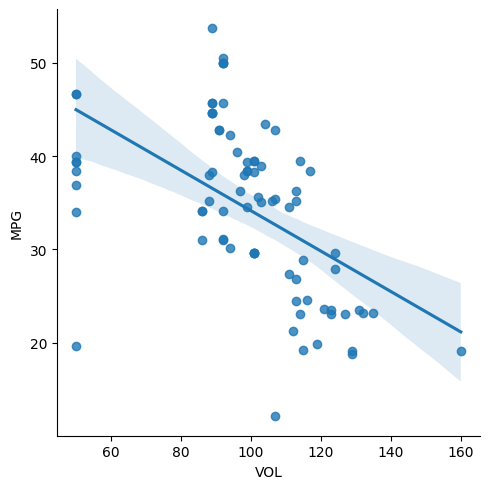

In [8]:
sns.lmplot(data =cars_data , x='VOL',y='MPG')

In [9]:
# Test 1 Linearity failed.

#### Test 2 : Normality test

(array([15., 35.,  9.,  6.,  9.,  0.,  2.,  2.,  1.,  2.]),
 array([ 49. ,  76.3, 103.6, 130.9, 158.2, 185.5, 212.8, 240.1, 267.4,
        294.7, 322. ]),
 <BarContainer object of 10 artists>)

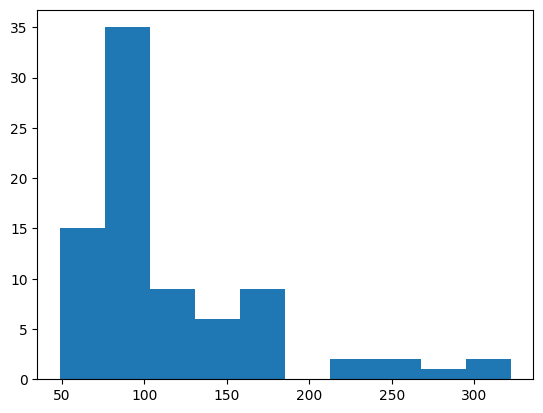

In [10]:
plt.hist(cars_data['HP'])

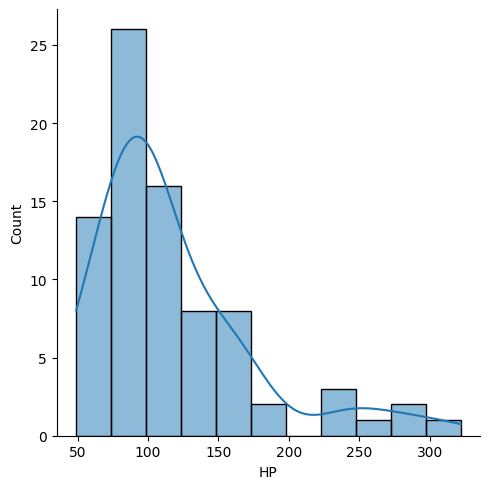

In [11]:
sns.displot(cars_data['HP'],kde=True)

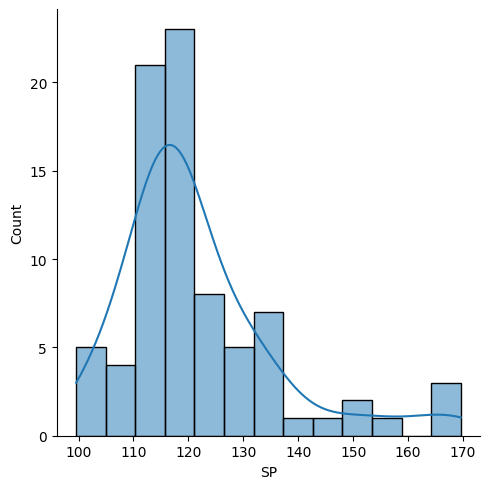

In [12]:
sns.displot(cars_data['SP'],kde=True)

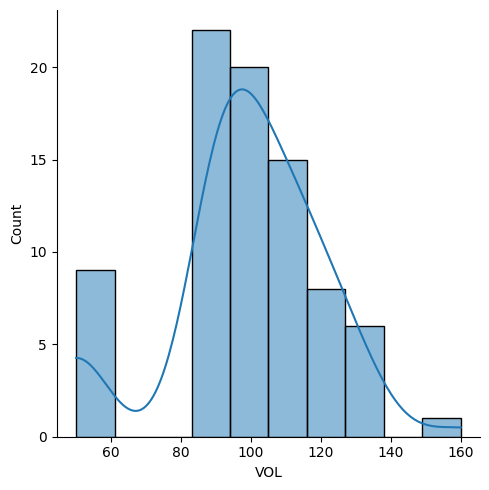

In [13]:
sns.displot(cars_data['VOL'],kde=True)

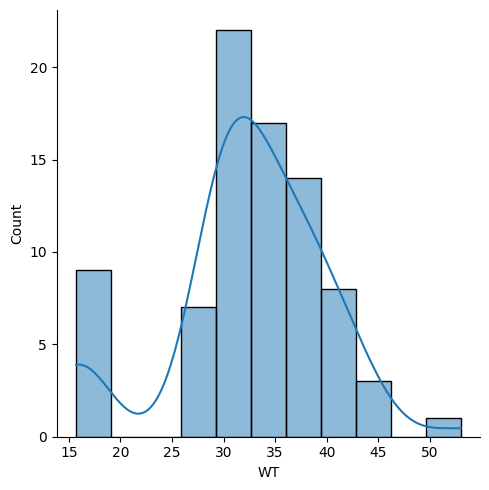

In [14]:
sns.displot(cars_data['WT'],kde=True)

In [15]:
# Test 2 Normality test failed

#### Test 3: Multicollinearity test

<Axes: >

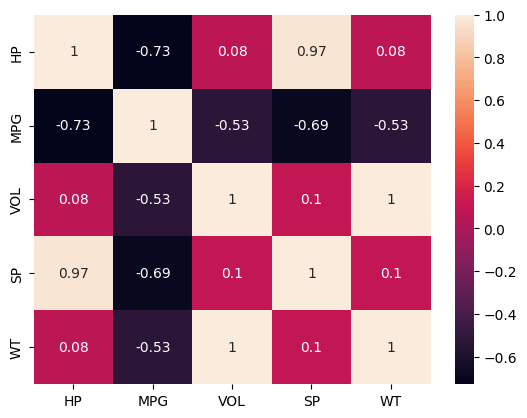

In [16]:
sns.heatmap(cars_data.corr().round(2),annot = True)

In [17]:
# Test 3 - There is multicollinearity in the data

#### Test 4 - Autoregression

In [18]:
# No date /time filed in the data
# Autoregression Pssed

### 4. Data Preparation

In [19]:
# segrigae x and y from the data
x = cars_data[['HP','VOL','SP','WT']]
x

,HP,VOL,SP,WT
0,49,89,104.185353,28.762059
1,55,92,105.461264,30.466833
2,55,92,105.461264,30.193597
3,70,92,113.461264,30.632114
4,53,92,104.461264,29.889149
...,...,...,...,...
76,322,50,169.598513,16.132947
77,238,115,150.576579,37.923113
78,263,50,151.598513,15.769625
79,295,119,167.944460,39.423099


In [20]:
y = cars_data['MPG']
y

0     53.700681
1     50.013401
2     50.013401
3     45.696322
4     50.504232
        ...    
76    36.900000
77    19.197888
78    34.000000
79    19.833733
80    12.101263
Name: MPG, Length: 81, dtype: float64

In [21]:
# All other features are in number so there is no data to prepare

### 5. Model building

In [22]:
X_train, X_test, y_train, y_test = train_test_split(x,y,test_size=0.20,
                                                    shuffle=True,random_state=39)

In [23]:
train_data = pd.concat([X_train,y_train],axis = 1)

In [24]:
test_data = pd.concat([X_test,y_test],axis = 1)

In [25]:
linear_model = LinearRegression()

### 6. Model Training

In [26]:
linear_model.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [27]:
linear_model.intercept_

np.float64(30.863969582690395)

In [28]:
linear_model.coef_ # slope of 4 inputs (hp,vol,sp,wt)

array([-0.20891736, -0.44859925,  0.39756814,  0.74939898])

### 7. Model Testing

In [29]:
y_pred_train = linear_model.predict(X_train)

In [30]:
y_pred_test = linear_model.predict(X_test)

### 8. Model evaluation

#### 8.1 Train data evaluation metrics

In [31]:
error_train = y_train - y_pred_train

In [32]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error,r2_score

In [33]:
print("Mean abs error:",mean_absolute_error(y_train , y_pred_train))
print("Mean squared error:",mean_squared_error(y_train , y_pred_train))
print("Root Mean square error:",root_mean_squared_error(y_train , y_pred_train))
print("R2 score:",r2_score(y_train , y_pred_train))

Mean abs error: 3.2012150714516427
Mean squared error: 19.089081593222737
Root Mean square error: 4.369105353870828
R2 score: 0.785511148545091


##### Linear statistics model

In [34]:
import statsmodels.formula.api as smf

In [35]:
linear_stats_model_train = smf.ols(formula = 'MPG ~ HP + VOL + SP + WT' , data = train_data).fit() # X_train, X_test, y_train, y_test

In [36]:
linear_stats_model_train.rsquared,linear_stats_model_train.rsquared_adj

(np.float64(0.785511148545091), np.float64(0.7709695314973005))

#### 8.2 Test data evaluation metrics

In [37]:
error_test = y_test - y_pred_test

In [38]:
print("Mean abs error:",mean_absolute_error(y_test , y_pred_test))
print("Mean squared error:",mean_squared_error(y_test , y_pred_test))
print("Root Mean square error:",root_mean_squared_error(y_test , y_pred_test))
print("R2 score:",r2_score(y_test , y_pred_test))

Mean abs error: 3.544847462445437
Mean squared error: 18.605741923593598
Root Mean square error: 4.3134373675287785
R2 score: 0.6742656188779668


##### Linear statistics model

In [39]:
linear_stats_model_test = smf.ols(formula = 'MPG ~ HP + VOL + SP + WT' , data = test_data).fit() 

In [40]:
linear_stats_model_test.rsquared,linear_stats_model_test.rsquared_adj

(np.float64(0.7148844907281979), np.float64(0.6198459876375972))

#### Test 5 Homoscadasticity

Text(0, 0.5, 'error')

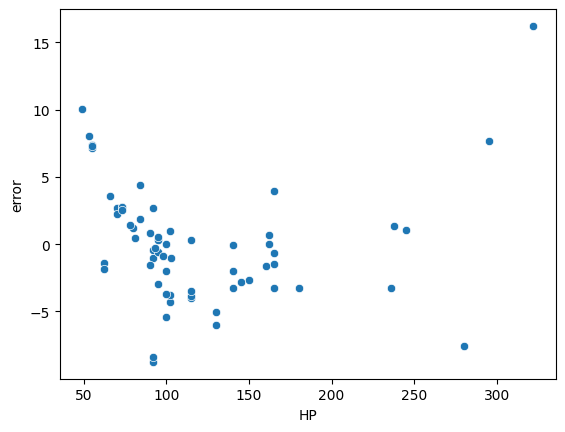

In [41]:
sns.scatterplot(data = cars_data ,x= "HP",y=error_train)
plt.ylabel("error")

Text(0, 0.5, 'error')

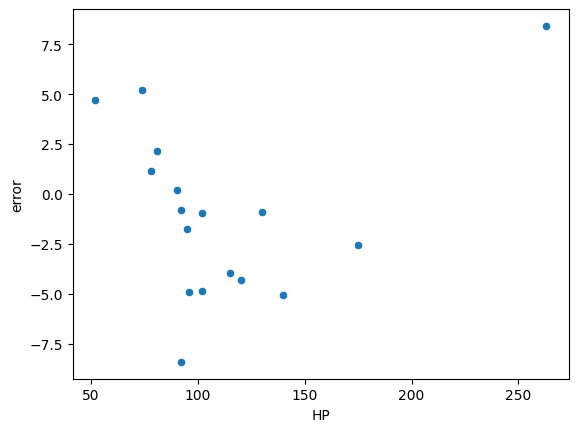

In [42]:
sns.scatterplot(data = cars_data ,x= "HP",y=error_test)
plt.ylabel("error")

Text(0, 0.5, 'error')

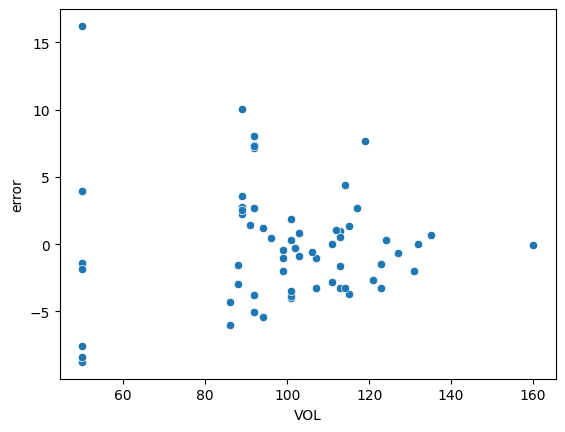

In [43]:
sns.scatterplot(data = cars_data ,x= "VOL",y=error_train)
plt.ylabel("error")

Text(0, 0.5, 'error')

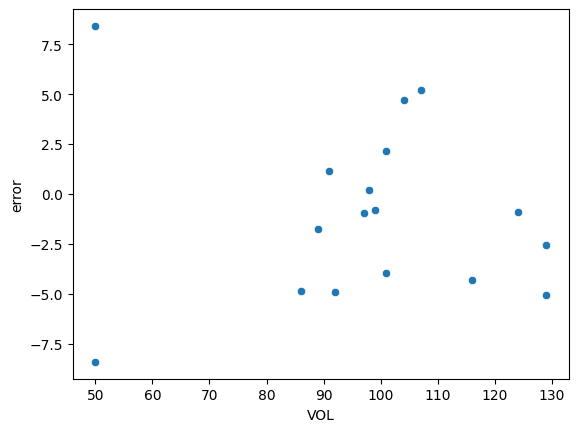

In [44]:
sns.scatterplot(data = cars_data ,x= "VOL",y=error_test)
plt.ylabel("error")

In [45]:
# Test 5 Homoscadasticity test failed

#### Test 6 Zero residual mean test 

<Axes: xlabel='MPG'>

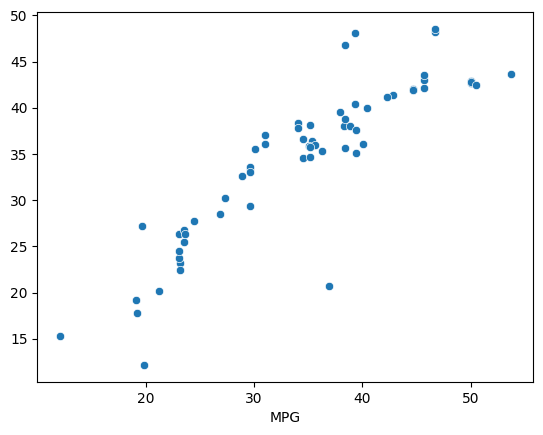

In [46]:
sns.scatterplot(x= y_train,y=y_pred_train)

In [47]:
# Test 6 Zero residual mean test is failed

### 9. Model Deployment

In [48]:
from pickle import dump
import pickle

In [49]:
dump(obj = linear_model,file = open(file='Linear_intelligence_file.pkl',mode = 'wb'))

In [50]:
linear_intel_pkl = pickle.load(file = open(file='Linear_intelligence_file.pkl',mode = 'rb'))
linear_intel_pkl

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [51]:
linear_intel_pkl.predict(X_train)

array([41.89628054, 26.38609015, 42.07702446, 12.16303412, 34.52575526,
       35.69223589, 42.65747208, 41.34955653, 38.01859985, 42.86223517,
       36.42604235, 48.14732398, 38.07433509, 38.34751251, 46.79706605,
       43.67671968, 36.07416242, 20.20537937, 34.62102918, 35.28191364,
       43.03288125, 35.53110997, 23.2252933 , 38.14092639, 26.77567354,
       35.90243506, 33.44838768, 23.72299158, 36.56497682, 33.6316289 ,
       15.34606235, 37.85934605, 28.49167917, 30.18720947, 29.35542643,
       27.76838402, 48.53081051, 39.9896832 , 24.54534383, 43.48935178,
       42.74356528, 33.089099  , 22.4838039 , 19.13892647, 25.47890945,
       36.06937777, 39.49278487, 42.1539605 , 17.83671666, 48.1028897 ,
       20.67959658, 35.94085181, 40.36779855, 35.05196059, 41.90759263,
       37.5547103 , 32.55740408, 42.44958569, 37.01397216, 27.23405593,
       38.80868098, 26.28110061, 35.73268282, 41.13063143])